# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Style commun à tous les graphiques du notebook
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 14,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
})
ROUGE = "#A71E36"
GRIS = "#898781"
COULEURS_COMMUNES = {
    "Cap-Haïtien": "#2a78d6",
    "Delmas": "#eb6834",
    "Port-au-Prince": "#1baf7a",
    "Pétion-Ville": "#eda100",
}
COULEURS_TYPES = {"Commercial": ROUGE, "Résidentiel": GRIS}

brut = pd.read_csv("donnees/consommation_brut.csv")

print("Forme :", brut.shape)
print("Lignes en double :", brut.duplicated().sum())
pd.DataFrame({"type": brut.dtypes, "manquants": brut.isna().sum()})

Forme : (300, 4)
Lignes en double : 12


,type,manquants
mois,str,0
quartier,str,0
kwh,str,9
heures_courant,float64,0


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
print("Écritures différentes :", brut["quartier"].nunique())
print(sorted(brut["quartier"].unique()))

Écritures différentes : 43
[' Bas-Peu-de-Chose', ' Carénage', ' Delmas 33', ' Delmas 65', ' Delmas 75', ' Morne Calvaire', ' Petite-Anse', ' Place Saint-Pierre', ' Thomassin', 'BAS-PEU-DE-CHOSE', 'BOIS-VERNA', 'Bas-Peu-de-Chose', 'Bas-Peu-de-Chose ', 'Bois-Verna', 'CARÉNAGE', 'CENTRE-VILLE', 'Carénage', 'Carénage ', 'Centre-ville', 'Centre-ville ', 'DELMAS 33', 'Delmas 33', 'Delmas 33 ', 'Delmas 65', 'Delmas 75', 'Delmas 75 ', 'Morne Calvaire', 'PLACE SAINT-PIERRE', 'Petite-Anse', 'Place Saint-Pierre', 'Place Saint-Pierre ', 'RUE 15', 'Rue 15', 'Rue 15 ', 'THOMASSIN', 'Thomassin', 'Thomassin ', 'bas-peu-de-chose', 'carénage', 'centre-ville', 'delmas 65', 'delmas 75', 'place saint-pierre']


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
nombres = pd.to_numeric(brut["kwh"], errors="coerce")
non_convertis = brut.loc[nombres.isna() & brut["kwh"].notna(), "kwh"]

print(len(non_convertis), "valeurs de kwh ne sont pas des nombres, par exemple :")
non_convertis.head(8).tolist()

52 valeurs de kwh ne sont pas des nombres, par exemple :


['184410 kWh',
 '206280 kWh',
 '215140 kWh',
 '251 900',
 '274520 kWh',
 '301740 kWh',
 '233010 kWh',
 '155930 kWh']

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.copy()

propre["kwh"] = propre["kwh"].str.replace("kWh", "").str.replace(" ", "")
propre["kwh"] = pd.to_numeric(propre["kwh"])

print("Type de kwh :", propre["kwh"].dtype)
print("Manquants dans kwh :", propre["kwh"].isna().sum())

Type de kwh : float64
Manquants dans kwh : 9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
quartiers = pd.read_csv("donnees/quartiers.csv")

# "bas-peu-de-chose" -> "Bas-Peu-de-Chose", à partir des noms officiels
noms_officiels = dict(zip(quartiers["quartier"].str.lower(), quartiers["quartier"]))
propre["quartier"] = propre["quartier"].str.strip().str.lower().map(noms_officiels)

print("Quartiers :", propre["quartier"].nunique())
print("Noms perdus par map :", propre["quartier"].isna().sum())

Quartiers :

 12
Noms perdus par map : 0


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
avant = len(propre)
propre = propre.drop_duplicates()
print("Doublons supprimés :", avant - len(propre))

avant = len(propre)
propre = propre.dropna(subset=["kwh"])
print("Lignes sans kwh supprimées :", avant - len(propre))

print("Forme :", propre.shape)

Doublons supprimés : 12
Lignes sans kwh supprimées : 9
Forme : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
mediane = propre.groupby("quartier")["kwh"].transform("median")
trop_grands = propre["kwh"] > 3 * mediane

print(trop_grands.sum(), "relevés dépassent 3 fois la médiane de leur quartier :")
display(propre[trop_grands])

propre.loc[trop_grands, "kwh"] = propre.loc[trop_grands, "kwh"] / 10
propre["kwh"] = propre["kwh"].astype(int)  # plus aucun manquant : on revient aux entiers

print("Maximum de kwh :", propre["kwh"].max())

4 relevés dépassent 3 fois la médiane de leur quartier :


,mois,quartier,kwh,heures_courant
90,2025-02,Delmas 33,3602600.0,10.1
140,2025-02,Delmas 75,2012700.0,11.1
200,2024-02,Morne Calvaire,1439200.0,11.4
251,2024-01,Rue 15,997700.0,5.9


Maximum de kwh : 742780


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
reference = pd.read_csv("donnees/consommation.csv")
print("Référence :", reference.shape, "(elle garde aussi les 9 mois sans kwh dans le brut)")

# Mêmes lignes : les couples mois-quartier de propre, dans le même ordre. Mêmes colonnes : celles de propre.
memes_lignes = propre[["mois", "quartier"]].merge(reference, on=["mois", "quartier"], how="left")

propre = propre.reset_index(drop=True)
propre.equals(memes_lignes[propre.columns])

Référence : (288, 5) (elle garde aussi les 9 mois sans kwh dans le brut)


True

## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
print("Avant :", len(propre), "lignes")
avec_quartiers = propre.merge(quartiers, on="quartier", how="left")
print("Après :", len(avec_quartiers), "lignes")

avec_quartiers["kwh_par_abonne"] = (avec_quartiers["kwh"] / avec_quartiers["abonnes"]).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4].astype(int)

avec_quartiers.head()

Avant : 279 lignes


Après : 279 lignes


,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee
0,2024-01,Bas-Peu-de-Chose,184410,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024
1,2024-02,Bas-Peu-de-Chose,195930,11.9,Port-au-Prince,Résidentiel,2150,91.1,2024
2,2024-03,Bas-Peu-de-Chose,186560,10.2,Port-au-Prince,Résidentiel,2150,86.8,2024
3,2024-04,Bas-Peu-de-Chose,236730,12.2,Port-au-Prince,Résidentiel,2150,110.1,2024
4,2024-05,Bas-Peu-de-Chose,206280,10.2,Port-au-Prince,Résidentiel,2150,95.9,2024


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
meteo = pd.read_csv("donnees/meteo.csv")

print("Avant :", len(avec_quartiers), "lignes")
avec_meteo = avec_quartiers.merge(meteo, on=["mois", "commune"], how="left")
print("Après :", len(avec_meteo), "lignes")
print("Températures manquantes :", avec_meteo["temperature_c"].isna().sum())

Avant : 279 lignes
Après : 279 lignes
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)

df = pd.read_csv("donnees/consommation_propre.csv")
print("Forme :", df.shape)
df.head()

Forme : (279, 11)


,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee,temperature_c,pluie_mm
0,2024-01,Bas-Peu-de-Chose,184410,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024,25.7,33
1,2024-02,Bas-Peu-de-Chose,195930,11.9,Port-au-Prince,Résidentiel,2150,91.1,2024,25.5,40
2,2024-03,Bas-Peu-de-Chose,186560,10.2,Port-au-Prince,Résidentiel,2150,86.8,2024,27.2,99
3,2024-04,Bas-Peu-de-Chose,236730,12.2,Port-au-Prince,Résidentiel,2150,110.1,2024,27.4,119
4,2024-05,Bas-Peu-de-Chose,206280,10.2,Port-au-Prince,Résidentiel,2150,95.9,2024,28.1,185


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

Consommation moyenne par abonné, en kWh par mois :
type
Commercial     393.2
Résidentiel    117.4



,quartier,type,kwh_par_abonne
0,Centre-ville,Commercial,468.7
1,Place Saint-Pierre,Commercial,458.3
2,Delmas 33,Commercial,374.4
3,Rue 15,Commercial,268.5
4,Morne Calvaire,Résidentiel,166.1
5,Thomassin,Résidentiel,146.0
6,Delmas 65,Résidentiel,134.9
7,Bois-Verna,Résidentiel,130.1
8,Delmas 75,Résidentiel,118.6
9,Bas-Peu-de-Chose,Résidentiel,100.2


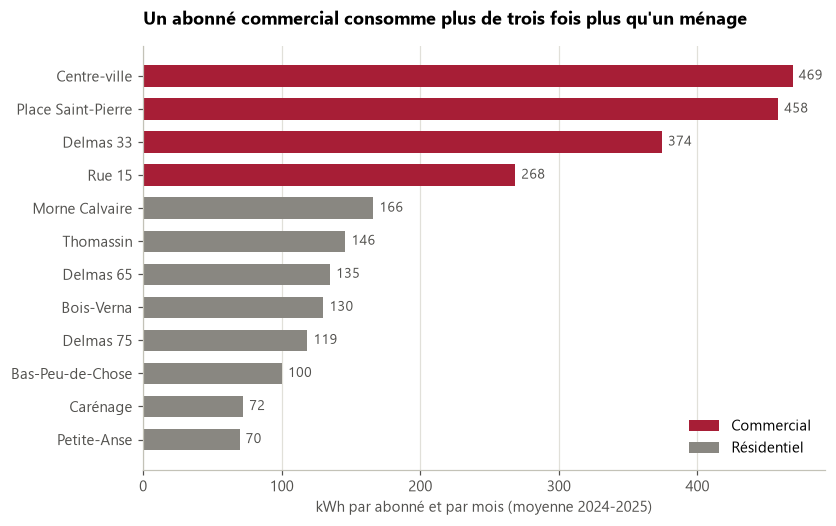

In [12]:
par_type = df.groupby("type")["kwh_par_abonne"].mean().round(1)
print("Consommation moyenne par abonné, en kWh par mois :")
print(par_type.to_string(), end="\n\n")

classement = (
    df.groupby(["quartier", "type"], as_index=False)["kwh_par_abonne"]
    .mean()
    .round(1)
    .sort_values("kwh_par_abonne", ascending=False, ignore_index=True)
)
display(classement)

fig, ax = plt.subplots(figsize=(8, 5))
for type_quartier, groupe in classement.groupby("type"):
    barres = ax.barh(groupe.index, groupe["kwh_par_abonne"], height=0.65,
                     color=COULEURS_TYPES[type_quartier], label=type_quartier)
    ax.bar_label(barres, fmt="%.0f", padding=4, color="#52514e", fontsize=9)
ax.set_yticks(classement.index, classement["quartier"])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("kWh par abonné et par mois (moyenne 2024-2025)")
ax.set_title("Un abonné commercial consomme plus de trois fois plus qu'un ménage")
ax.legend(loc="lower right")
plt.show()

**Ce qu'on en conclut :** Un abonné commercial consomme en moyenne 393.2 kWh par mois, contre 117.4 kWh pour un abonné résidentiel : 3.3 fois plus. Les quatre quartiers commerciaux occupent les quatre premières places, menés par Centre-ville (468.7 kWh) et Place Saint-Pierre (458.3 kWh). Chez les résidentiels, on va de 69.6 kWh à Petite-Anse à 166.1 kWh à Morne Calvaire, plus du double ; les deux derniers, Carénage et Petite-Anse, sont à Cap-Haïtien.

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

annee,2024,2025,hausse_%
commune,,,
Cap-Haïtien,4.59,5.62,22.5
Pétion-Ville,8.60,9.68,12.6
Port-au-Prince,10.09,10.31,2.3
Delmas,11.61,11.74,1.1


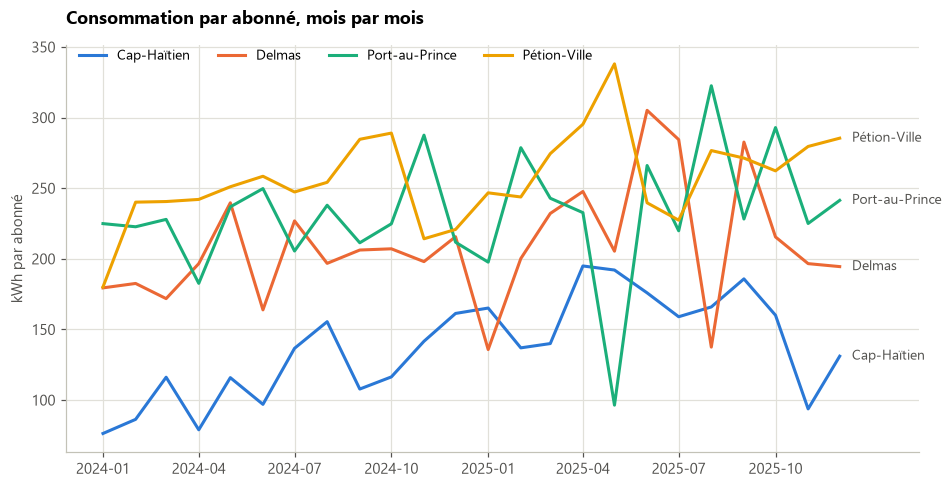

In [13]:
totaux = df.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")
totaux["hausse_%"] = ((totaux[2025] - totaux[2024]) / totaux[2024] * 100).round(1)
totaux[[2024, 2025]] = (totaux[[2024, 2025]] / 1_000_000).round(2)
totaux = totaux.sort_values("hausse_%", ascending=False)
display(totaux)

par_mois = df.pivot_table(index="mois", columns="commune", values="kwh_par_abonne", aggfunc="mean")
par_mois.index = pd.to_datetime(par_mois.index)

fig, ax = plt.subplots(figsize=(10, 4.8))
for commune in par_mois.columns:
    serie = par_mois[commune]
    ax.plot(serie.index, serie, color=COULEURS_COMMUNES[commune], linewidth=2, label=commune)
    ax.annotate(commune, (serie.index[-1], serie.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color="#52514e")
ax.set_xticks(par_mois.index[::3], par_mois.index[::3].strftime("%Y-%m"))
ax.set_xlim(right=par_mois.index[-1] + pd.Timedelta(days=75))
ax.set_ylabel("kWh par abonné")
ax.set_title("Consommation par abonné, mois par mois")
ax.legend(ncols=4, loc="upper left", bbox_to_anchor=(0, 1.02), fontsize=9)
plt.show()

**Ce qu'on en conclut :** La consommation augmente dans les quatre communes entre 2024 et 2025. Cap-Haïtien, la commune qui consomme le moins, progresse le plus : de 4.59 à 5.62 millions de kWh, soit +22.5 % (22.46 % exactement ; on trouve 22.4 % si l'on part des totaux déjà arrondis). Delmas, la plus grosse consommatrice, est presque stable (+1.1 %), mais il lui manque trois relevés en 2025 et aucun en 2024 : sa hausse est sous-estimée. Sur les courbes, Pétion-Ville est le plus souvent en tête par abonné (256.8 kWh par mois en moyenne) et Cap-Haïtien presque toujours en dernier (137.1 kWh). Les creux de Port-au-Prince en mai 2025 et de Delmas en août 2025 ne sont pas de vraies baisses : il manque ces mois-là le relevé d'un quartier commercial (Centre-ville, Delmas 33), ce qui tire la moyenne vers le bas.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

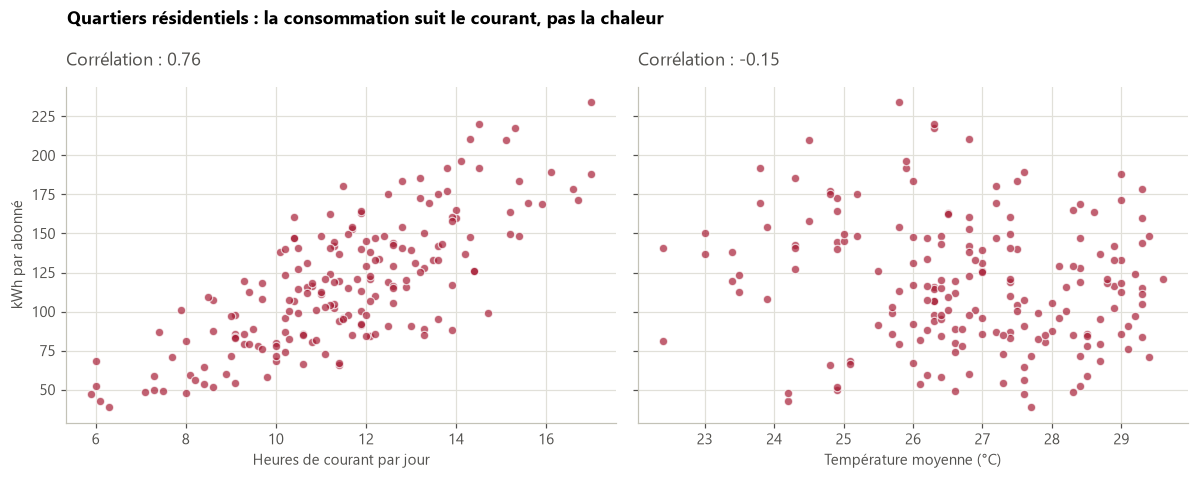

Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


In [14]:
residentiel = df[df["type"] == "Résidentiel"]

corr_courant = residentiel["kwh_par_abonne"].corr(residentiel["heures_courant"])
corr_chaleur = residentiel["kwh_par_abonne"].corr(residentiel["temperature_c"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, colonne, etiquette, corr in [
    (ax1, "heures_courant", "Heures de courant par jour", corr_courant),
    (ax2, "temperature_c", "Température moyenne (°C)", corr_chaleur),
]:
    ax.scatter(residentiel[colonne], residentiel["kwh_par_abonne"], s=30, alpha=0.7,
               color=ROUGE, edgecolor="white", linewidth=0.8)
    ax.set_xlabel(etiquette)
    ax.set_title(f"Corrélation : {corr:.2f}", fontweight="normal", color="#52514e")
ax1.set_ylabel("kWh par abonné")
fig.suptitle("Quartiers résidentiels : la consommation suit le courant, pas la chaleur",
             x=0.06, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

print(f"Corrélation avec les heures de courant : {corr_courant:.2f}")
print(f"Corrélation avec la température : {corr_chaleur:.2f}")

**Ce qu'on en conclut :** Dans les quartiers résidentiels, la consommation par abonné suit nettement les heures de courant : la corrélation est de 0.76, et le nuage monte régulièrement, d'environ 50 kWh vers 6 heures de courant par jour à plus de 150 kWh au-delà de 15 heures. Avec la température, la corrélation est faible et même légèrement négative (-0.15) : les mois les plus chauds ne sont pas ceux où l'on consomme le plus. On ne garde que les quartiers résidentiels pour ne pas mélanger deux niveaux de consommation très différents (117.4 contre 393.2 kWh par abonné).

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

,médiane,Q1,Q3
commune,,,
Cap-Haïtien,10.0,8.3,11.70
Port-au-Prince,11.6,10.7,13.10
Pétion-Ville,11.6,10.4,13.05
Delmas,11.9,10.1,13.00


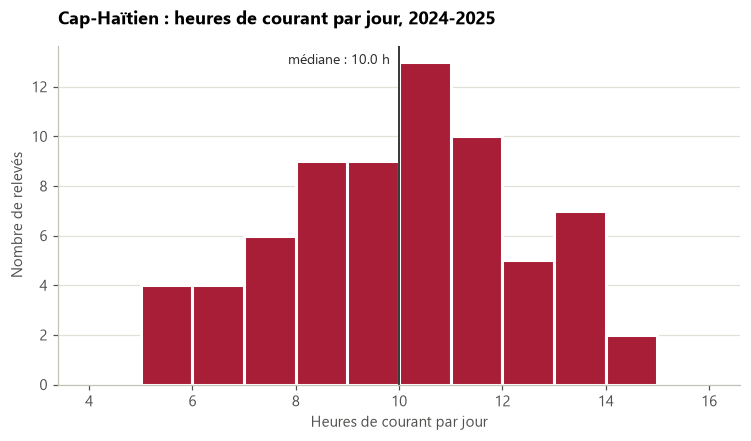

3 relevés de 2025 ont moins de 8 heures de courant par jour :


,mois,quartier,commune,heures_courant
81,2025-01,Delmas 33,Delmas,7.4
227,2025-08,Carénage,Cap-Haïtien,7.3
253,2025-11,Rue 15,Cap-Haïtien,5.9


In [15]:
quartiles = (
    df.groupby("commune")["heures_courant"]
    .quantile([0.25, 0.5, 0.75])
    .unstack()
    .rename(columns={0.25: "Q1", 0.5: "médiane", 0.75: "Q3"})
    [["médiane", "Q1", "Q3"]]
    .sort_values("médiane")
)
display(quartiles)

cap = df[df["commune"] == "Cap-Haïtien"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cap["heures_courant"], bins=range(4, 17), color=ROUGE, edgecolor="white", linewidth=2)
ax.axvline(cap["heures_courant"].median(), color="#2b2b2b", linewidth=1.2)
ax.annotate(f"médiane : {cap['heures_courant'].median():.1f} h",
            (cap["heures_courant"].median(), ax.get_ylim()[1]), xytext=(-6, -12),
            textcoords="offset points", ha="right", fontsize=9, color="#2b2b2b")
ax.grid(axis="x", visible=False)
ax.set_xlabel("Heures de courant par jour")
ax.set_ylabel("Nombre de relevés")
ax.set_title("Cap-Haïtien : heures de courant par jour, 2024-2025")
plt.show()

coupures = df[(df["annee"] == 2025) & (df["heures_courant"] < 8)]
print(len(coupures), "relevés de 2025 ont moins de 8 heures de courant par jour :")
coupures[["mois", "quartier", "commune", "heures_courant"]]

**Ce qu'on en conclut :** Cap-Haïtien est la commune la plus touchée par les coupures : la moitié de ses relevés ont 10.0 heures de courant par jour ou moins, contre 11.6 à 11.9 heures dans les trois autres communes, et un quart descendent sous 8.3 heures. En 2025, 3 relevés passent sous 8 heures par jour : Delmas 33 en janvier (7.4 h), Carénage en août (7.3 h) et Rue 15 en novembre (5.9 h), dont deux à Cap-Haïtien. C'est aussi à Cap-Haïtien que les ménages consomment le moins (70.8 kWh par abonné et par mois dans ses quartiers résidentiels), ce qui va dans le sens de la partie 6.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [16]:
mediane_quartier = df.groupby("quartier")["kwh"].median()

records = df.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]
records["fois_la_mediane"] = (records["kwh"] / records["quartier"].map(mediane_quartier)).round(1)
records

,mois,quartier,type,kwh,fois_la_mediane
87,2025-07,Delmas 33,Commercial,742780,1.7
56,2024-11,Centre-ville,Commercial,597730,1.4
88,2025-09,Delmas 33,Commercial,591420,1.4


**Ce qu'on en conclut :** Les trois plus gros relevés viennent de quartiers commerciaux : Delmas 33 en juillet 2025 (742 780 kWh), Centre-ville en novembre 2024 (597 730 kWh), puis Delmas 33 en septembre 2025 (591 420 kWh). Ce ne sont pas des erreurs de saisie comme celles corrigées à la question 7 : ils restent à 1.7 fois la médiane de leur quartier au plus, loin de la règle des 3 fois. Ces trois mois ont tous eu beaucoup de courant (16.9, 17.5 et 14.8 heures par jour), ce qui rejoint encore la partie 6.

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

**Réponse au directeur :** la consommation suit les heures de courant, pas la chaleur. Dans les quartiers résidentiels, la consommation par abonné a une corrélation de 0.76 avec les heures de courant contre -0.15 seulement avec la température, et Cap-Haïtien, où le courant manque le plus (10.0 heures par jour en médiane), est aussi la commune où les ménages consomment le moins (70.8 kWh par abonné et par mois). Une corrélation montre que deux mesures varient ensemble, mais elle ne prouve pas que l'une cause l'autre : d'autres facteurs, comme les revenus, les équipements ou les tarifs, peuvent jouer, et ces relevés ne couvrent que 24 mois.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.